Training RNNs on ODR
====================



## Notebook Settings



In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
# %run ../../../notebooks/setup.py
# %matplotlib inline
# %config InlineBackend.figure_format = 'png'

REPO_ROOT = "/home/leon/models/NeuroFlame"
pal = sns.color_palette("tab10")

## Imports



In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
# import torchmetrics
import torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, DataLoader

In [3]:
import sys
sys.path.insert(0, '../../../')
sys.path.append('/home/kostas/NeuroFlame') 

import pandas as pd
import torch.nn as nn
from time import perf_counter
from scipy.stats import circmean

from src.network import Network
from src.plot_utils import plot_con
from src.decode import decode_bump, circcvl, decode_bump_torch
from src.lr_utils import masked_normalize, clamp_tensor, normalize_tensor

## Helpers



### plots



In [4]:
def add_vlines(model, ax=None):

    if ax is None:
        for i in range(len(model.T_STIM_ON)):
            plt.axvspan(model.T_STIM_ON[i], model.T_STIM_OFF[i], alpha=0.25)
    else:
        for i in range(len(model.T_STIM_ON)):
            ax.axvspan(model.T_STIM_ON[i], model.T_STIM_OFF[i], alpha=0.25)

In [5]:
def plot_rates_selec(rates, idx=0, thresh=0.5, figname='fig.svg'):
        fig, ax = plt.subplots(1, 2, figsize=[2*width, height])
        r_max = thresh * np.max(rates[idx])

        idx = np.random.randint(0, 96)
        vmin, vmax = np.percentile(rates[idx].reshape(-1), [5, 95])

        ax[0].imshow(rates[idx].T, aspect='auto', cmap='jet', vmin=vmin, vmax=vmax)
        ax[0].set_ylabel('Neuron #')
        ax[0].set_xlabel('Step')

        idx = np.random.randint(0, 96)
        vmin, vmax = np.percentile(rates[idx].reshape(-1), [5, 95])
        ax[1].imshow(rates[idx].T, aspect='auto', cmap='jet', vmin=vmin, vmax=vmax)
        ax[1].set_ylabel('Neuron #')
        ax[1].set_xlabel('Step')
        # ax[1].set_ylim([745, 755])
        # plt.savefig(figname, dpi=300)
        plt.show()

In [6]:
def plot_m0_m1_phi(model, rates, idx, figname='fig.svg'):

      m0, m1, phi = decode_bump_torch(rates, axis=-1, RET_TENSOR=0)
      print(m0.shape, m1.shape, phi.shape)

      fig, ax = plt.subplots(1, 3, figsize=[2*width, height])

      xtime = np.linspace(0, model.DURATION, m0.shape[-1])
      idx = np.random.randint(0, 96, 16)

      ax[0].plot(xtime, m0[idx].T)
      #ax[0].set_ylim([0, 360])
      #ax[0].set_yticks([0, 90, 180, 270, 360])
      ax[0].set_ylabel('$\mathcal{F}_0$ (Hz)')
      ax[0].set_xlabel('Time (s)')
      add_vlines(model, ax[0])

      ax[1].plot(xtime, m1[idx].T)
      # ax[1].set_ylim([0, 360])
      # ax[1].set_yticks([0, 90, 180, 270, 360])
      ax[1].set_ylabel('$\mathcal{F}_1$ (Hz)')
      ax[1].set_xlabel('Time (s)')
      add_vlines(model, ax[1])

      ax[2].plot(xtime, phi[idx].T * 180 / np.pi, alpha=.5)
      ax[2].set_ylim([0, 360])
      ax[2].set_yticks([0, 90, 180, 270, 360])
      ax[2].set_ylabel('Phase (°)')
      ax[2].set_xlabel('Time (s)')
      add_vlines(model, ax[2])

      plt.savefig(figname, dpi=300)
      plt.show()

### Data Split



In [7]:
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit

def split_data(X, Y, train_perc=0.8, batch_size=32, shuffle=True):

    # if shuffle:
    #     X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
    #                                                         train_size=train_perc,
    #                                                         stratify=Y[:, 0].cpu().numpy(),
    #                                                         shuffle=True)
    # else:
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y,
                                                        train_size=train_perc,
                                                        stratify=None,
                                                        shuffle=False)

    plt.hist(Y_train[Y_train!=-999].cpu() * 180 / np.pi, bins=15, label='train')
    plt.hist(Y_test[Y_test!=-999].cpu() * 180 / np.pi, bins=15, label='test')
    plt.xlabel('Target Loc. (°)')
    plt.ylabel('Count')
    plt.show()

    print(X_train.shape, X_test.shape)
    print(Y_train.shape, Y_test.shape)

    train_dataset = TensorDataset(X_train, Y_train)
    val_dataset = TensorDataset(X_test, Y_test)

    # Create data loaders
    train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=shuffle)
    val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader

### Optimization



In [8]:
def training_step(dataloader, model, loss_fn, optimizer, penalty=None, lbd=0.001, clip_grad=0, zero_grad=0):
    device = torch.device(DEVICE if torch.cuda.is_available() else "cpu")

    model.train()
    total_loss = 0.0
    total_batches = len(dataloader)

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()

        rates = model(X)
        loss = loss_fn(rates, y)

        # Initialize reg_loss as a scalar tensor
        reg_loss = torch.tensor(0.0, device=device)

        # Only apply the penalty once per step
        if penalty is not None:
            for param in model.parameters():
                if penalty == 'l1':
                    reg_loss += torch.sum(torch.abs(param))
                elif penalty == 'l2':
                    reg_loss += torch.sum(param ** 2)  # Better to use param ** 2

        loss = loss + lbd * reg_loss

        # Backpropagation
        loss.backward()

        # Clip gradients
        if clip_grad:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
            #torch.nn.utils.clip_grad_value_(model.parameters(), clip_value=1.0)

        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / total_batches
    return avg_loss

In [9]:
def validation_step(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    device = torch.device(DEVICE if torch.cuda.is_available() else "cpu")

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            rates = model(X)
            batch_loss = loss_fn(rates, y)
            val_loss += batch_loss.item() * X.size(0)

    val_loss /= size
    return val_loss

In [10]:
def optimization(model, train_loader, val_loader, loss_fn, optimizer, num_epochs=100, penalty=None, lbd=1, thresh=0.005, zero_grad=0, gamma=0.9):

    # Choose one scheduler
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)
    # scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=10, factor=0.1, verbose=True)
    # scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.1)

    device = torch.device(DEVICE if torch.cuda.is_available() else 'cpu')
    model.to(device)

    loss_list = []
    val_loss_list = []

    for epoch in range(num_epochs):
        loss = training_step(train_loader, model, loss_fn, optimizer, penalty, lbd, zero_grad=zero_grad)
        val_loss = validation_step(val_loader, model, loss_fn)

        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_loss)
        else:
            scheduler.step()

        loss_list.append(loss)
        val_loss_list.append(val_loss)

        print(f'Epoch {epoch+1}/{num_epochs}, Training Loss: {loss:.4f}, Validation Loss: {val_loss:.4f}')

        if val_loss < thresh and loss < thresh:
            print(f'Stopping training as loss has fallen below the threshold: {loss}, {val_loss}')
            break

        if val_loss > 300:
            print(f'Stopping training as loss is too high: {val_loss}')
            break

        if torch.isnan(torch.tensor(loss)):
            print(f'Stopping training as loss is NaN.')
            break

    return loss_list, val_loss_list

### Loss



In [11]:
import torch

def skewed_gaussian_loss(theta_batch, y_pred, theta_bias, sigma=30, alpha=1.0):
    """
    Asymmetric likelihood loss with skew controlled by alpha.
    - theta_batch: True stimulus angles (batch_size)
    - y_pred: Network predictions (batch_size)
    - sigma: Base noise level (degrees)
    - alpha: Skew magnitude/direction (alpha > 0: skew away from theta_bias)
    """
    # Compute angular difference (handling circularity)
    # delta = torch.remainder(theta_batch - theta_bias + torch.pi, 2.0 * torch.pi) - torch.pi
    delta = theta_batch - theta_bias
    delta = (delta + torch.pi) % (2 * torch.pi) - torch.pi

    # Determine skew direction: alpha should be positive if stimulus > theta_bias
    sign = torch.where(delta > 0, 1.0, -1.0)  # 1 if stimulus is clockwise from bias
    alpha_scaled = alpha * sign  # Skew direction depends on stimulus location

    # Skewed Gaussian likelihood
    delta = theta_batch - y_pred
    delta = (delta + torch.pi) % (2 * torch.pi) - torch.pi
    z = delta / sigma
    likelihood = torch.exp(-0.5 * z**2) * (1 + torch.erf(alpha_scaled * z / torch.sqrt(torch.tensor(2.0).to(y_pred.device))))

    # Negative log-likelihood loss
    loss = -torch.log(likelihood + 1e-6)
    return loss

In [12]:
def gaussian_loss(theta_batch, y_pred, sigma=30):
        delta = y_pred - theta_batch
        delta = (delta + torch.pi) % (2 * torch.pi) - torch.pi

        likelihood = torch.exp(-0.5 * (delta / sigma)**2)

        return -torch.log(likelihood + 1e-6)

In [13]:
def polar_loss(theta_batch, y_pred):
        loss = nn.MSELoss(reduction='none')
        predicted_sin = torch.sin(y_pred)
        predicted_cos = torch.cos(y_pred)

        target_sin = torch.sin(theta_batch)
        target_cos = torch.cos(theta_batch)

        loss_sin = loss(predicted_sin, target_sin)
        loss_cos = loss(predicted_cos, target_cos)

        loss_angular = (loss_sin + loss_cos)

        return loss_angular

In [14]:
import torch
import torch.nn as nn

class CircularAngleLoss(nn.Module):
    def __init__(self, mode='angular', reduction='mean'):
        super().__init__()
        self.mode = mode
        self.reduction = reduction
        self.mse = nn.MSELoss(reduction=reduction)

    def forward(self, pred_angle, target_angle):
        if self.mode == 'polar':
            pred_sin, pred_cos = torch.sin(pred_angle), torch.cos(pred_angle)
            target_sin, target_cos = torch.sin(target_angle), torch.cos(target_angle)
            loss_sin = self.mse(pred_sin, target_sin)
            loss_cos = self.mse(pred_cos, target_cos)
            return (loss_sin + loss_cos) / 2

        elif self.mode == 'angular':
            error = 1 - torch.cos(pred_angle - target_angle)
            if self.reduction == 'mean':
                return error.mean()
            elif self.reduction == 'sum':
                return error.sum()
            else:
                return error
        else:
            raise ValueError(f"Unknown loss mode: {self.mode}")

In [15]:
import torch
import torch.nn as nn
import torch.distributions

class VonMisesNLLLoss(nn.Module):
    def __init__(self, kappa=4.0, reduction='none'):
        super().__init__()
        self.kappa = kappa
        self.reduction = reduction

    def forward(self, pred_angle, target_angle):
        # pred_angle and target_angle in radians, same shape
        vm = torch.distributions.VonMises(pred_angle, self.kappa)
        nll = -vm.log_prob(target_angle)
        if self.reduction == 'mean':
            return nll.mean()
        elif self.reduction == 'sum':
            return nll.sum()
        else:
            return nll  # (no reduction)

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AngularErrorLoss(nn.Module):
    def __init__(self, thresh=1, reg_tuning=0.1, sigma_stimulus=30):
        super(AngularErrorLoss, self).__init__()

        self.loss = nn.MSELoss(reduction='none')
        # self.loss = nn.SmoothL1Loss(reduction='none')

        # self.polar_loss = VonMisesNLLLoss(reduction='none')
        self.polar_loss = CircularAngleLoss(reduction='none')

        self.thresh = thresh
        self.reg_tuning = reg_tuning
        self.sigma_stimulus = sigma_stimulus * torch.pi / 180.0

    def forward(self, readout, theta_batch):
        m0, m1, y_pred = decode_bump_torch(readout, axis=-1, device=readout.device)

        valid_mask = theta_batch != -999
        invalid_mask = ~valid_mask
        total_loss = 0

        # angular loss (Dcos, Dsin)
        loss_polar = self.polar_loss(theta_batch, y_pred) * valid_mask
        loss_angular = loss_polar.sum()

        # loss_gaussian = gaussian_loss(theta_batch, y_pred, sigma=self.sigma_stimulus) * valid_mask
        # loss_angular = loss_gaussian.sum()

        total_loss += loss_angular

        # imposing tuning strength
        regularization = F.relu(self.thresh * m0 - m1) * valid_mask
        total_loss += self.reg_tuning * regularization.sum()

        # normalize over batch and time points
        total_loss /= valid_mask.sum()

        # imposing zero tuning in invalid mask
        loss_zero = self.loss(m1, 0.0 * m1) * invalid_mask
        total_loss += loss_zero.sum() / invalid_mask.sum()

        return total_loss

### Other



In [17]:
import pickle as pkl

def pkl_save(obj, name, path="."):
    pkl.dump(obj, open(path + "/" + name + ".pkl", "wb"))


def pkl_load(name, path="."):
    return pkl.load(open(path + "/" + name + '.pkl', "rb"))

In [18]:
def convert_seconds(seconds):
      h = seconds // 3600
      m = (seconds % 3600) // 60
      s = seconds % 60
      return h, m, s

## Model



In [19]:
kwargs = {
    'GAIN': 1.0,
    'DURATION': 10.0,
    'T_STEADY': 4,

    'T_STIM_ON': [4.0, 6.0],
    'T_STIM_OFF': [5.0, 7.0],

    'Jab': [1.1, -1.3, 1, -1],
    'I0': [0.5, -2.0],
    'PHI0': [180.0, 180],
    'SIGMA0': [2.0, 0.0],
    'M0': 1,

    'RANDOM_DELAY': 1,
    'MIN_DELAY': 0,
    'MAX_DELAY': 3,

    'IF_FF_STP': 0,
    'FF_USE': 0.5,
    'TAU_FF_FAC': 0.0,
    'TAU_FF_REC': 0.5,

    'IS_STP': [1, 0, 0, 0],
    'USE': [0.05, 0.03, 0.03, 0.1],
    'TAU_FAC': [2.0, 2.0, 2.0, 0.0],
    'TAU_REC': [0.2, 0.2, 0.2, 0.1],
    'W_STP': [1.0, 3.0, 4.0, 1.0],

    'IF_NMDA': 1,
    'R_NMDA': 1.0,
    'TAU_NMDA': [0.4, 0.4],

    'IF_FF_ADAPT': 1,
    'A_FF_ADAPT': 0.2,
    'TAU_FF_ADAPT': 100.0,

    'IF_ADAPT': 1,
    'A_ADAPT': 2.0,
    'TAU_ADAPT': 150.0,
}

In [20]:
REPO_ROOT = "/home/leon/models/NeuroFlame"
conf_name = "train_odr_EI.yml"
DEVICE = 'cuda'

total_batches = 128 * 8
batch_size = 128
ratio = total_batches // batch_size

N_BATCH = int(batch_size * ratio)
print('N_BATCH', N_BATCH, 'batch_size', batch_size)

seed = np.random.randint(0, 1e6)
seed = 0
print('seed', seed)

N_BATCH 1024 batch_size 128
seed 0


In [21]:
model = Network(conf_name, REPO_ROOT, VERBOSE=0, DEVICE=DEVICE, SEED=seed, N_BATCH=N_BATCH, **kwargs)

1050
450
EE post 0 pre 0 Jab tensor(0.0696, device='cuda:0') torch.Size([1050, 1050])


## Training



In [22]:
model.J_STP.requires_grad = True

#### Parameters



In [23]:
for name, param in model.named_parameters():
      if param.requires_grad:
          print(name, param.shape)

Wab_train torch.Size([1050, 1050])
J_STP torch.Size([])


In [24]:
model.N_BATCH = N_BATCH
rwd_mask = torch.zeros((model.N_BATCH, int((model.N_STEPS-model.N_STEADY) / model.N_WINDOW)), device=DEVICE, dtype=torch.bool)
print('rwd_mask', rwd_mask.shape)

for i in range(model.N_BATCH):
    # from first stim onset to second stim onset
    mask = torch.arange((model.start_indices[0, i] - model.N_STEADY)/ model.N_WINDOW,
                        (model.start_indices[1, i] - model.N_STEADY) / model.N_WINDOW).to(torch.int)
    # print(mask)
    rwd_mask[i, mask] = True

idx = np.random.randint(N_BATCH)
print(torch.where(rwd_mask[idx]==1)[0])

rwd_mask torch.Size([1024, 131])
tensor([40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50], device='cuda:0')


#### Inputs and Labels



In [25]:
total_batches = N_BATCH // batch_size

print('total_batches', N_BATCH // batch_size)

labels = []
for _ in range(total_batches):
    batch_labels = torch.randint(0, 360, (batch_size, 1)).to(DEVICE)
    labels.append(batch_labels)

labels = torch.cat(labels, dim=0)
print(labels.shape)

total_batches 8
torch.Size([1024, 1])


In [26]:
model.PHI0 = torch.ones((N_BATCH, 2, 1), device=DEVICE, dtype=torch.float)
model.PHI0[:, 0] = labels * np.pi / 180.0

window_size = int((model.N_STEPS-model.N_STEADY) / model.N_WINDOW)
labels = labels.repeat(1, window_size) * np.pi / 180.0
labels[~rwd_mask] = -999

ff_input = model.init_ff_input()
print(model.PHI0.shape, ff_input.shape, labels.shape)

torch.Size([1024, 2, 1]) torch.Size([1024, 855, 1500]) torch.Size([1024, 131])


torch.Size([81720])
torch.Size([52424])


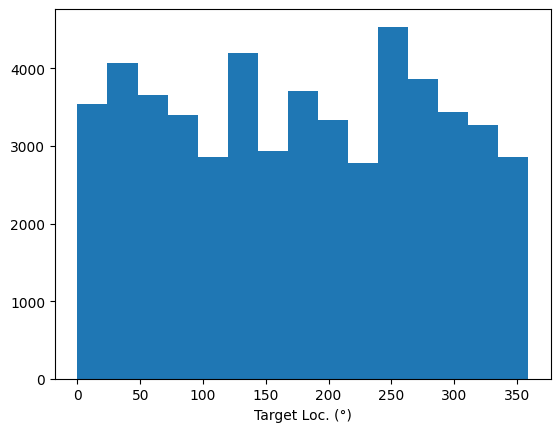

In [27]:
print(labels[labels==-999].shape)
print(labels[labels!=-999].shape)
plt.hist(labels[labels!=-999].cpu() * 180 / np.pi, bins=15)
plt.xlabel('Target Loc. (°)')
plt.show()

#### Run



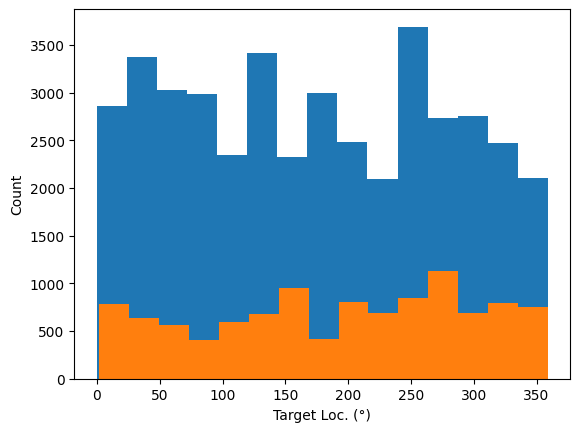

torch.Size([819, 855, 1500]) torch.Size([205, 855, 1500])
torch.Size([819, 131]) torch.Size([205, 131])


In [28]:
train_loader, val_loader = split_data(ff_input, labels, train_perc=0.8, batch_size=batch_size, shuffle=False)

In [29]:
criterion = AngularErrorLoss(thresh=0.75, sigma_stimulus=30)
learning_rate = 0.1
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [31]:
num_epochs = 5
start = perf_counter()
loss = optimization(model, train_loader, val_loader, criterion, optimizer, num_epochs, thresh=.005)
end = perf_counter()
print("Elapsed (with compilation) = %dh %dm %ds" % convert_seconds(end - start))

/pytorch/aten/src/ATen/native/cuda/IndexKernel.cu:113: operator(): block: [0,0,0], thread: [31,0,0] Assertion `-sizes[i] <= index && index < sizes[i] && "index out of bounds"` failed.
/pytorch/aten/src/ATen/native/cuda/IndexKernel.cu:113: operator(): block: [0,0,0], thread: [32,0,0] Assertion `-sizes[i] <= index && index < sizes[i] && "index out of bounds"` failed.
/pytorch/aten/src/ATen/native/cuda/IndexKernel.cu:113: operator(): block: [0,0,0], thread: [33,0,0] Assertion `-sizes[i] <= index && index < sizes[i] && "index out of bounds"` failed.
/pytorch/aten/src/ATen/native/cuda/IndexKernel.cu:113: operator(): block: [0,0,0], thread: [34,0,0] Assertion `-sizes[i] <= index && index < sizes[i] && "index out of bounds"` failed.
/pytorch/aten/src/ATen/native/cuda/IndexKernel.cu:113: operator(): block: [0,0,0], thread: [35,0,0] Assertion `-sizes[i] <= index && index < sizes[i] && "index out of bounds"` failed.
/pytorch/aten/src/ATen/native/cuda/IndexKernel.cu:113: operator(): block: [0,0,0

AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [ ]:
torch.save(model.state_dict(), '../models/odr_%d.pth' % seed)

## Testing



In [ ]:
model_state_dict = torch.load('../models/odr/odr_%d.pth' % seed);
model.load_state_dict(model_state_dict);
model.eval();

print(model.J_STP)

Parameter containing:
tensor(2.1821, device='cuda:0', requires_grad=True)

In [ ]:
with torch.no_grad():
    model.N_BATCH = N_BATCH

    labels = torch.randint(0, 360, (N_BATCH, 1)).to(DEVICE) * torch.pi / 180.0
    model.PHI0 = torch.ones((N_BATCH, 2, 1), device=DEVICE, dtype=torch.float)
    model.PHI0[:, 0] = labels


    ff_input = model.init_ff_input()
    print(model.PHI0.shape, ff_input.shape, labels.shape)

torch.Size([1024, 2, 1]) torch.Size([1024, 855, 1000]) torch.Size([1024, 1])

In [ ]:
plt.hist(labels[:, 0].cpu() * 180 / np.pi, bins='auto', density=True)
plt.xlabel('Target Loc. (°)')
plt.ylabel('Density')
plt.xticks(np.linspace(0, 360, 5))
# plt.savefig('./figs/memhist/targets.svg', dpi=300)
plt.show()

In [ ]:
with torch.no_grad():
    rates = model.forward(ff_input=ff_input).cpu().detach().numpy()
print('rates', rates.shape)

rates (1024, 131, 750)

In [ ]:
plot_rates_selec(rates=ff_input.cpu().detach().numpy(), idx=20, thresh=.5)

In [ ]:
plot_m0_m1_phi(model, ff_input.cpu().numpy()[..., model.slices[0]], 10)

(1024, 855) (1024, 855) (1024, 855)


In [ ]:
plot_rates_selec(rates=rates, idx=20, thresh=.5)

In [ ]:
plot_m0_m1_phi(model, rates, 4)

(1024, 131) (1024, 131) (1024, 131)


In [ ]:
# targets = (target_loc + np.pi) % (2 * np.pi) - np.pi

# fig, ax = plt.subplots(1, 2, figsize=[2*width, height])
# # ax[0].hist(targets[:, 0] * 180 / np.pi , bins=32 , histtype='step')
# ax[0].hist(errors2, bins=32, histtype='step')
# ax[0].set_xlabel('Encoding Errors (°)')

# ax[1].hist(errors, bins=32)
# ax[1].set_xlabel('Memory Errors (°)')
# # ax[1].set_xlim([-45, 45])
# plt.show()

## Connectivity



In [ ]:
model_state_dict = torch.load('../models/odr/odr_%d.pth' % seed);
model.load_state_dict(model_state_dict);
model.eval();

In [ ]:
from src.lr_utils import LowRankWeights, clamp_tensor
Cij = model.GAIN * ( model.W_stp_T[0]  + model.Wab_train[model.slices[0], model.slices[0]])
# Cij = model.Wab_train / model.Na[0] * model.J_STP
# Cij[Cij>0]= 1
Cij = clamp_tensor(Cij, 0, model.slices).cpu().detach().numpy()

Cij0 = pkl_load('matrix', path=".")
Kj0 = pkl_load( 'Kj', path=".")
Ki0 = pkl_load( 'Ki', path=".")

In [ ]:
plt.figure(figsize=(2.5*width, 1.5*height))  # Set the figure size (width, height) in inches

  ax1 = plt.subplot2grid((2, 3), (0, 0), rowspan=2)
  im = ax1.imshow(Cij, cmap='jet', aspect=1, vmin=0)
  ax1.set_xlabel("Presynaptic")
  ax1.set_ylabel("Postsynaptic")

  # Second column, first row
  ax2 = plt.subplot2grid((2, 3), (0, 1))
  Kj = np.sum(Cij, axis=0)  # sum over pres
  ax2.plot(circcvl(Kj-Kj0, windowSize=75))
  # ax2.set_xticklabels([])
  ax2.set_ylabel("$K_j$")

  # # Second column, second row
  ax3 = plt.subplot2grid((2, 3), (1, 1))
  Ki = np.sum(Cij, axis=1)  # sum over pres
  ax3.plot(circcvl(Ki-Ki0, windowSize=75))
  ax3.set_ylabel("$K_i$")

  ax4 = plt.subplot2grid((2, 3), (0, 2), rowspan=2)
  diags = []
  for i in range(int(Cij.shape[0] / 2)):
      diags.append(np.trace(Cij, offset=i) / Cij.shape[0])
  diags = np.array(diags)
  ax4.plot(diags)
  ax4.set_xlabel("Neuron #")
  ax4.set_ylabel("$P_{ij}$")

  plt.tight_layout()
  plt.show()

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=[2*width, height], sharey=1)

  Dij = Cij.flatten()
  np.random.shuffle(Dij)
  Dij = Dij.reshape(Cij.shape)

  im = ax[0].imshow(Dij, cmap='jet', aspect=1, vmin=0)
  ax[0].set_xlabel("Presynaptic")
  ax[0].set_ylabel("Postsynaptic")
  ax[0].set_title('Naive')
  # ax[0].set_xticks(np.linspace(0, 750, 4))
  # ax[0].set_yticks(np.linspace(0, 750, 4))

  im = ax[1].imshow(Cij, cmap='jet', aspect=1, vmin=0)
  ax[1].set_xlabel("Presynaptic")
  ax[1].set_ylabel("Postsynaptic")
  ax[1].set_title('Trained')
  # ax[1].set_xticks(np.linspace(0, 750, 4))
  # ax[1].set_yticks(np.linspace(0, 750, 4))
  plt.tight_layout()
  plt.show()